In [ ]:
This is an example using this package analyzing flow cytometry data. The dataset is downlaoded from zenodo. 

# library import

In [2]:
devtools::load_all()


ℹ Loading cytoTerra
Warning message:
“replacing previous import ‘scales::viridis_pal’ by ‘viridis::viridis_pal’ when loading ‘Spectre’”


# download data

In [ ]:
system('wget -O Brain_Tumor-Bearing_2026_01_30_10_15_14.fcs "https://zenodo.org/records/20628167/files/01%20Brain_Tumor-Bearing_2026_01_30_10_15_14.fcs?download=1"')

In [3]:
fcs_file = '/nfs/roberts/project/pi_hmk7/wh523/workspace/flow/Brain_Tumor-Bearing_2026_01_30_10_15_14.fcs'

# load data

In [4]:
project <- cytoTerra(fcs_file, sample_ids = 'A1', sample_names = 'glioma')
project$auto_gate_singlets()


Automatic singlet gating: 1 sample; gate name = 'Singlets'.

[1/1] Fitting singlet gate for sample 'A1'...

    Saved 'Singlets' for sample 'A1' using 3431 retained events (0 sec).

Automatic singlet gating completed.



# channels

In [6]:
project$get_channel_info()

sample_id,sample_name,parameter_index,channel,description,parameter_class,is_fluorescence_candidate,in_expression_matrix
<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<lgl>,<lgl>
A1,glioma,1,Time,NA,time_or_event,FALSE,TRUE
A1,glioma,2,UV1-A,NA,fluorescence_or_other,TRUE,TRUE
A1,glioma,3,UV2-A,NA,fluorescence_or_other,TRUE,TRUE
A1,glioma,4,UV3-A,NA,fluorescence_or_other,TRUE,TRUE
A1,glioma,5,UV4-A,NA,fluorescence_or_other,TRUE,TRUE
A1,glioma,6,UV5-A,NA,fluorescence_or_other,TRUE,TRUE
A1,glioma,7,UV6-A,NA,fluorescence_or_other,TRUE,TRUE
A1,glioma,8,UV7-A,NA,fluorescence_or_other,TRUE,TRUE
A1,glioma,9,UV8-A,NA,fluorescence_or_other,TRUE,TRUE


# manual gating

In [ ]:
## root [root]
##   └─ Singlets [polygon]
##     └─ UV10pos [polygon]
##     └─ UV2pos [polygon]
##     └─ YG1pos_UV10neg [polygon]


In [7]:
project$launch_gating_workspace(
  sample_id = "A1"
)



cytoTerra Shiny gating workspace
Open this URL in a new browser tab:
https://ood-bouchet.ycrc.yale.edu/node/a1114u28n01.mghpcc.ycrc.yale.edu/59092/proxy/3838/




Open cytoTerra manual-gating workspace


Listening on http://127.0.0.1:3838

Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”
Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”
Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”
Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”
Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”
Created polygon gate 'UV2pos' under parent 'Singlets' for sample 'A1'.

Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”
Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”
Warning message:
“Specifying width/height in layout() is now deprecated.
Please

# copy gate to all samples

In [ ]:
project$copy_gate_tree(
    from_sample = "A1",
    overwrite = FALSE,
    skip_existing = TRUE
)

# export gate tree

In [21]:
gating_file <- "~/workspace/flow/lymphoid_all_samples_gate_tree.rds"

project$export_all_gate_trees(
  file = gating_file
)

# plot gate

[1/1] Plotting 2D gate 'YG1pos_UV10neg' for sample 'A1'...



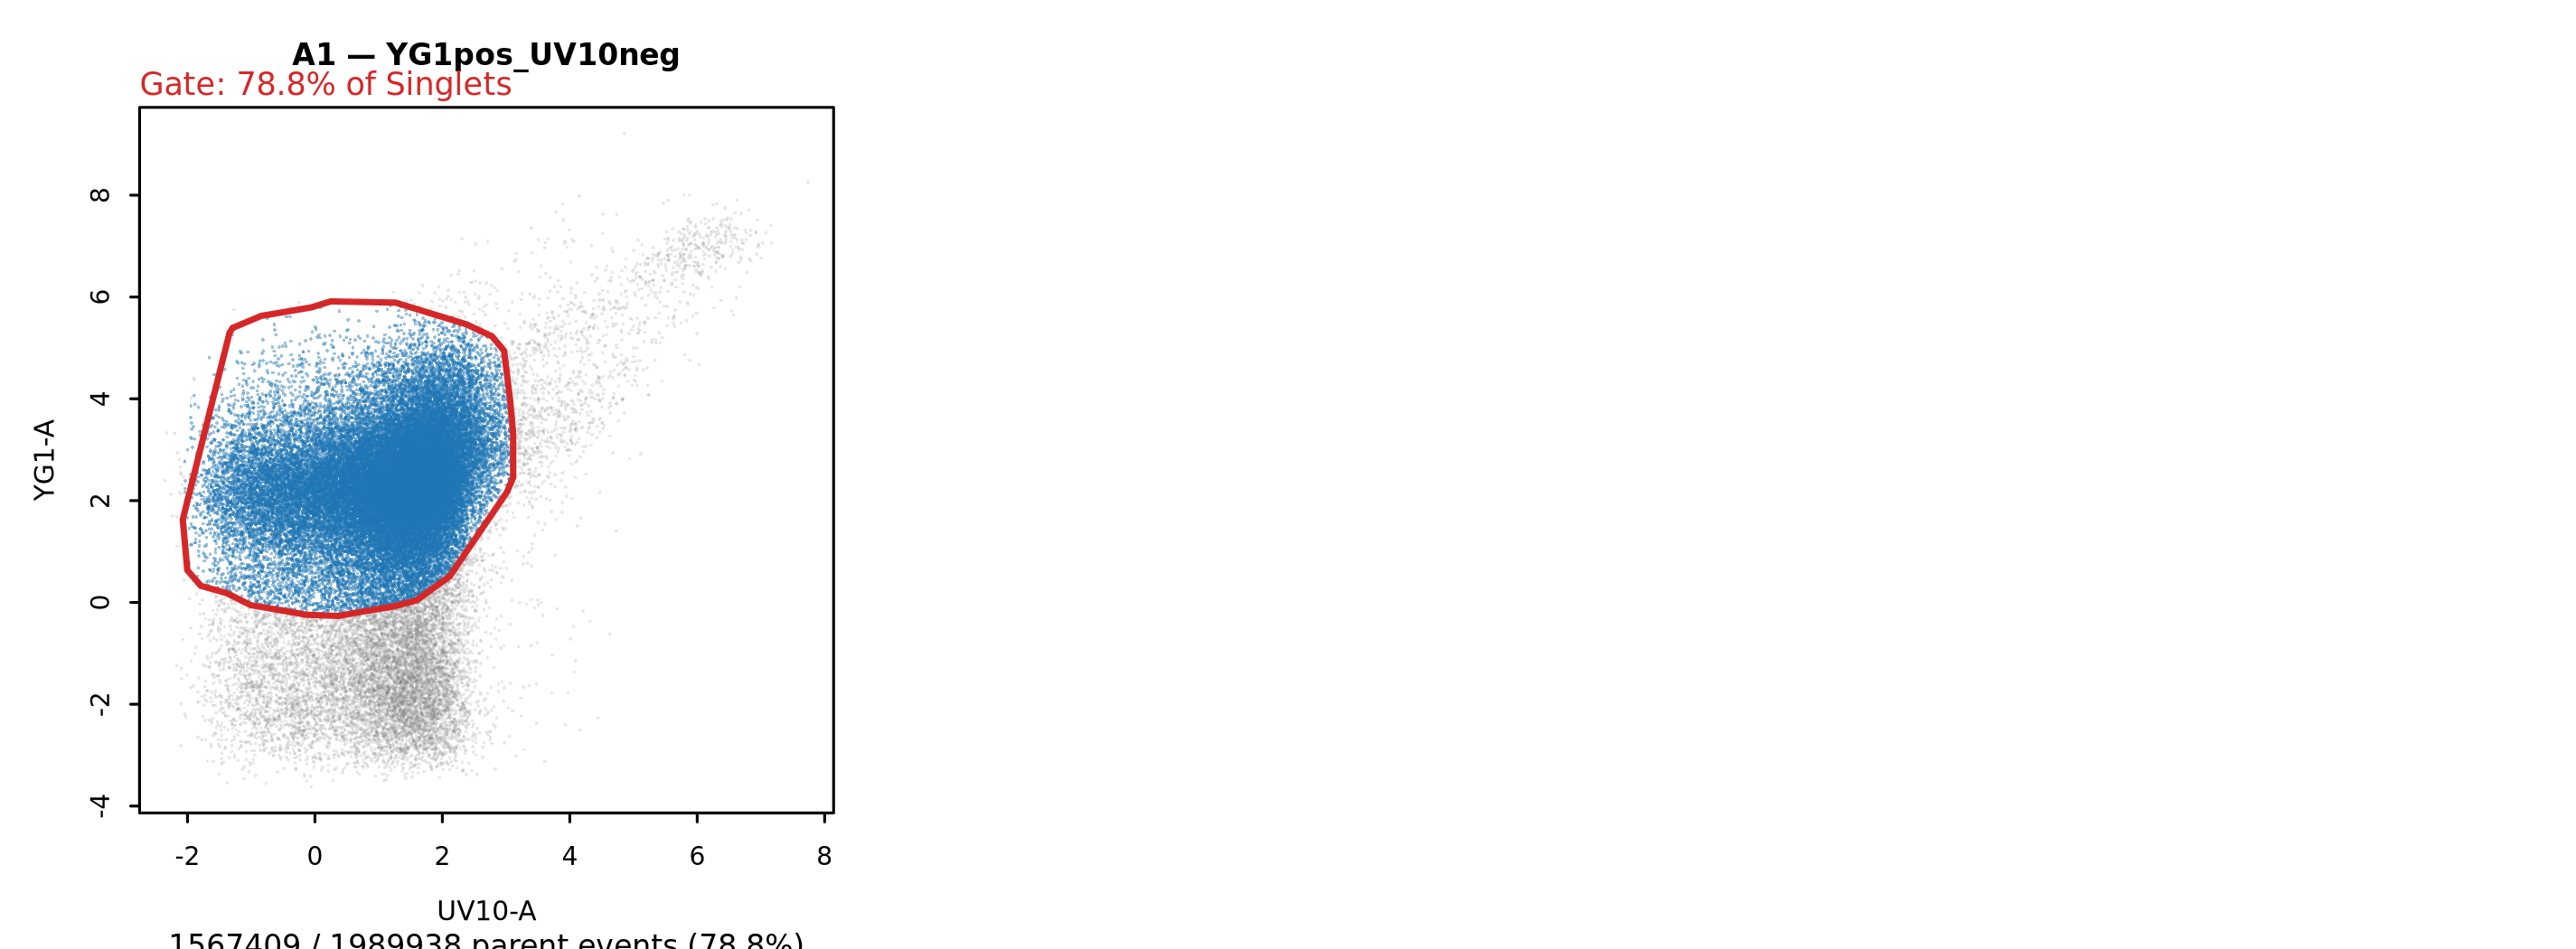

In [8]:
options(repr.plot.width=9.5, repr.plot.height=3.5, repr.plot.res=300)
project$plot_2d_gates(sample_ids = c('A1'), gate_name = 'YG1pos_UV10neg', layout = c(1,3), n_plot = 50000)

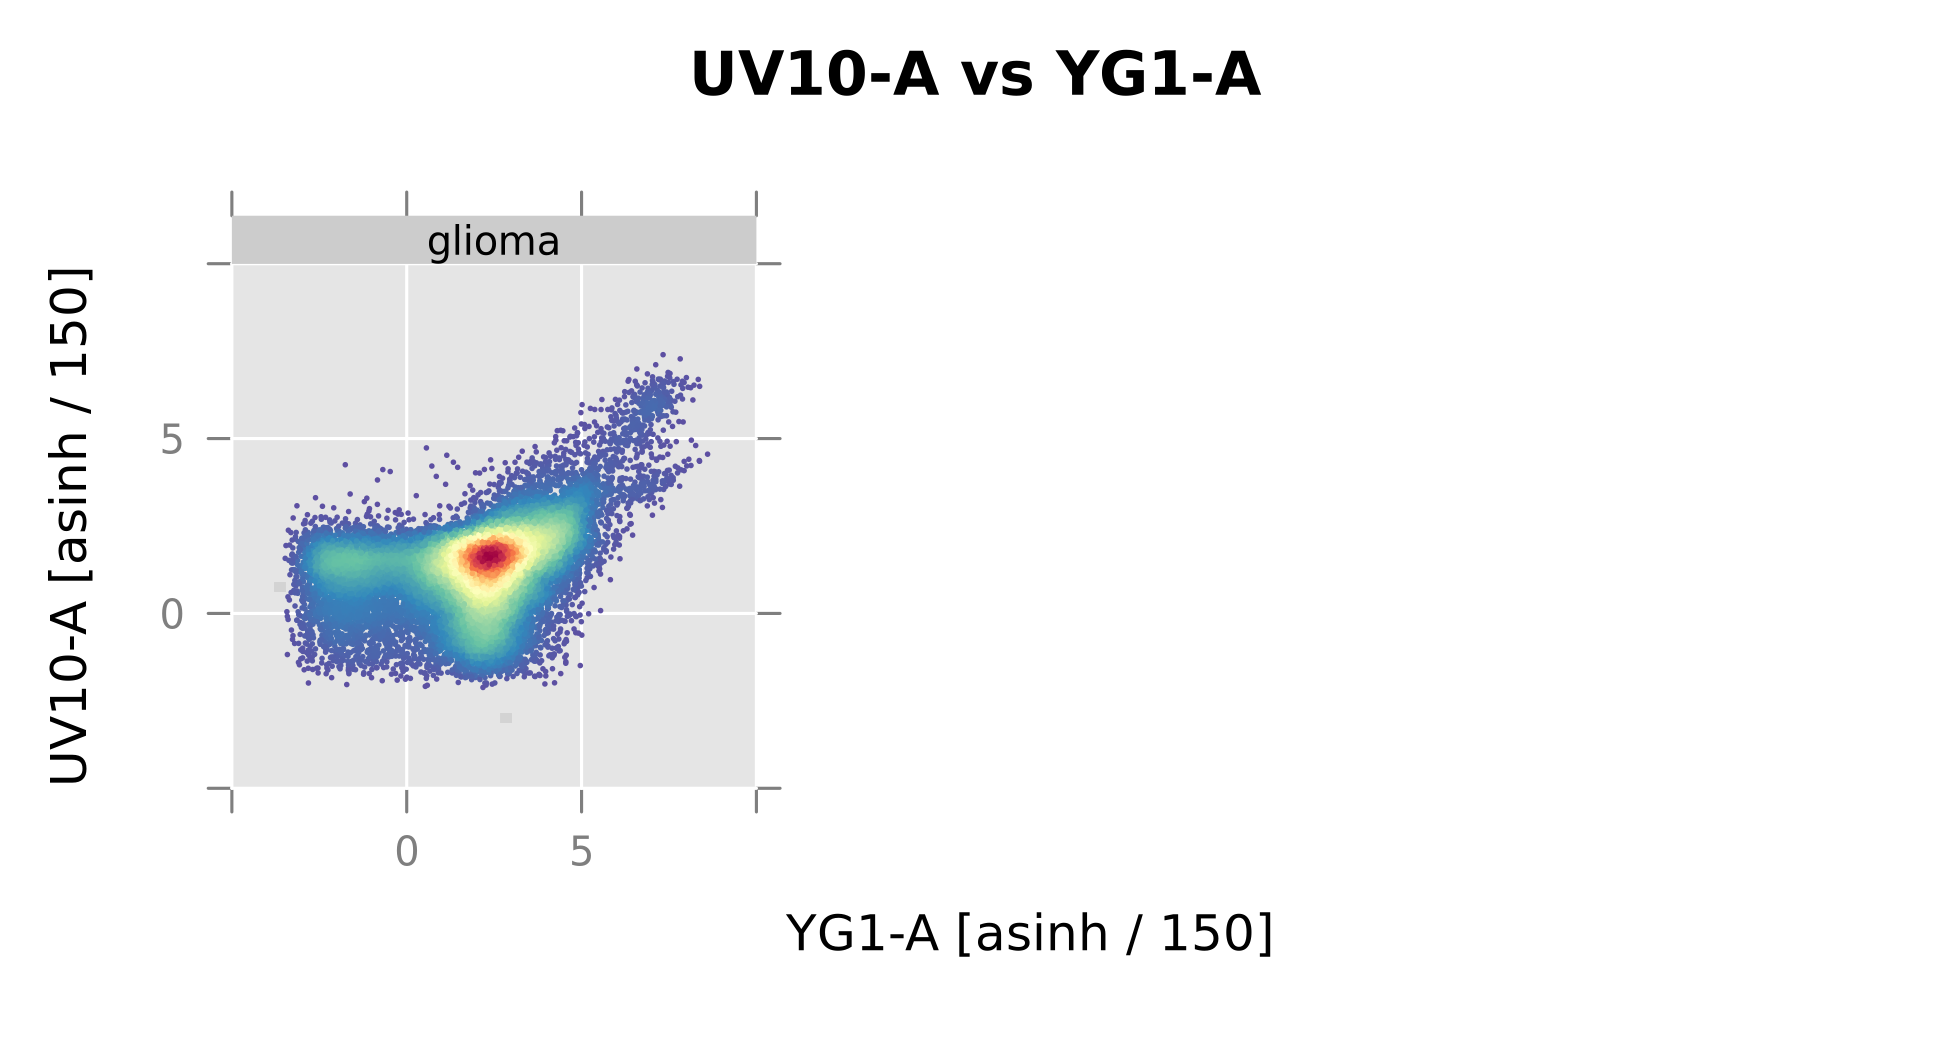

In [10]:
options(repr.plot.width=6.5, repr.plot.height=3.5, repr.plot.res=300)
project$plot_flowviz_xyplot(
    sample_ids = c("A1"),
    x_channel = "YG1-A", y_channel = "UV10-A", layout = c(1,3),
    xlim = c(-5, 10), ylim = c(-5, 10)
)

# 1st clustering run

## clustering analysis

In [12]:
cluster_markers = project$get_channel_info()$channel
cluster_markers = cluster_markers[grep('UV|B|YG|R|V', cluster_markers) ]
cluster_markers

[1] "UV1-A"   "UV2-A"   "UV3-A"   "UV4-A"   "UV5-A"   "UV6-A"   "UV7-A"  
 [8] "UV8-A"   "UV9-A"   "UV10-A"  "UV11-A"  "UV12-A"  "UV13-A"  "UV14-A" 
[15] "UV15-A"  "UV16-A"  "SSC-B-H" "SSC-B-A" "B1-A"    "B2-A"    "B3-A"   
[22] "B4-A"    "B5-A"    "B6-A"    "B7-A"    "B8-A"    "B9-A"    "B10-A"  
[29] "B11-A"   "B12-A"   "B13-A"   "B14-A"   "YG1-A"   "YG2-A"   "YG3-A"  
[36] "YG4-A"   "YG5-A"   "YG6-A"   "YG7-A"   "YG8-A"   "YG9-A"   "YG10-A" 
[43] "R1-A"    "R2-A"    "R3-A"    "R4-A"    "R5-A"    "R6-A"    "R7-A"   
[50] "R8-A"

In [13]:
project$run_harmony_umap_flowsom_fastpg(
  result_name = "run1",
  gate_names = c("Singlets"),
  markers = cluster_markers
)


Extracting events from gate: 'Singlets'.

Running PCA, FlowSOM, FastPG, FastPG metaclustering, and UMAP on 1989938 events across 1 batch.

Warning message:
“Only one batch is present; Harmony was skipped and PCA coordinates will be used.”
Running FlowSOM.

Running FastPG with k = 30 using 8 threads.

Running FlowSOM consensus metaclustering of FastPG clusters.

Running UMAP.

14:38:50 UMAP embedding parameters a = 0.9922 b = 1.112

14:38:50 Read 1989938 rows and found 30 numeric columns

14:38:50 Using Annoy for neighbor search, n_neighbors = 30

14:38:51 Building Annoy index with metric = euclidean, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:40:22 Writing NN index file to temp file /tmp/RtmpjbHhEB/fileea738705081c2

14:40:23 Searching Annoy index using 8 threads, search_k = 3000

14:44:00 Annoy recall 

## plot clustering

### UMAP plot

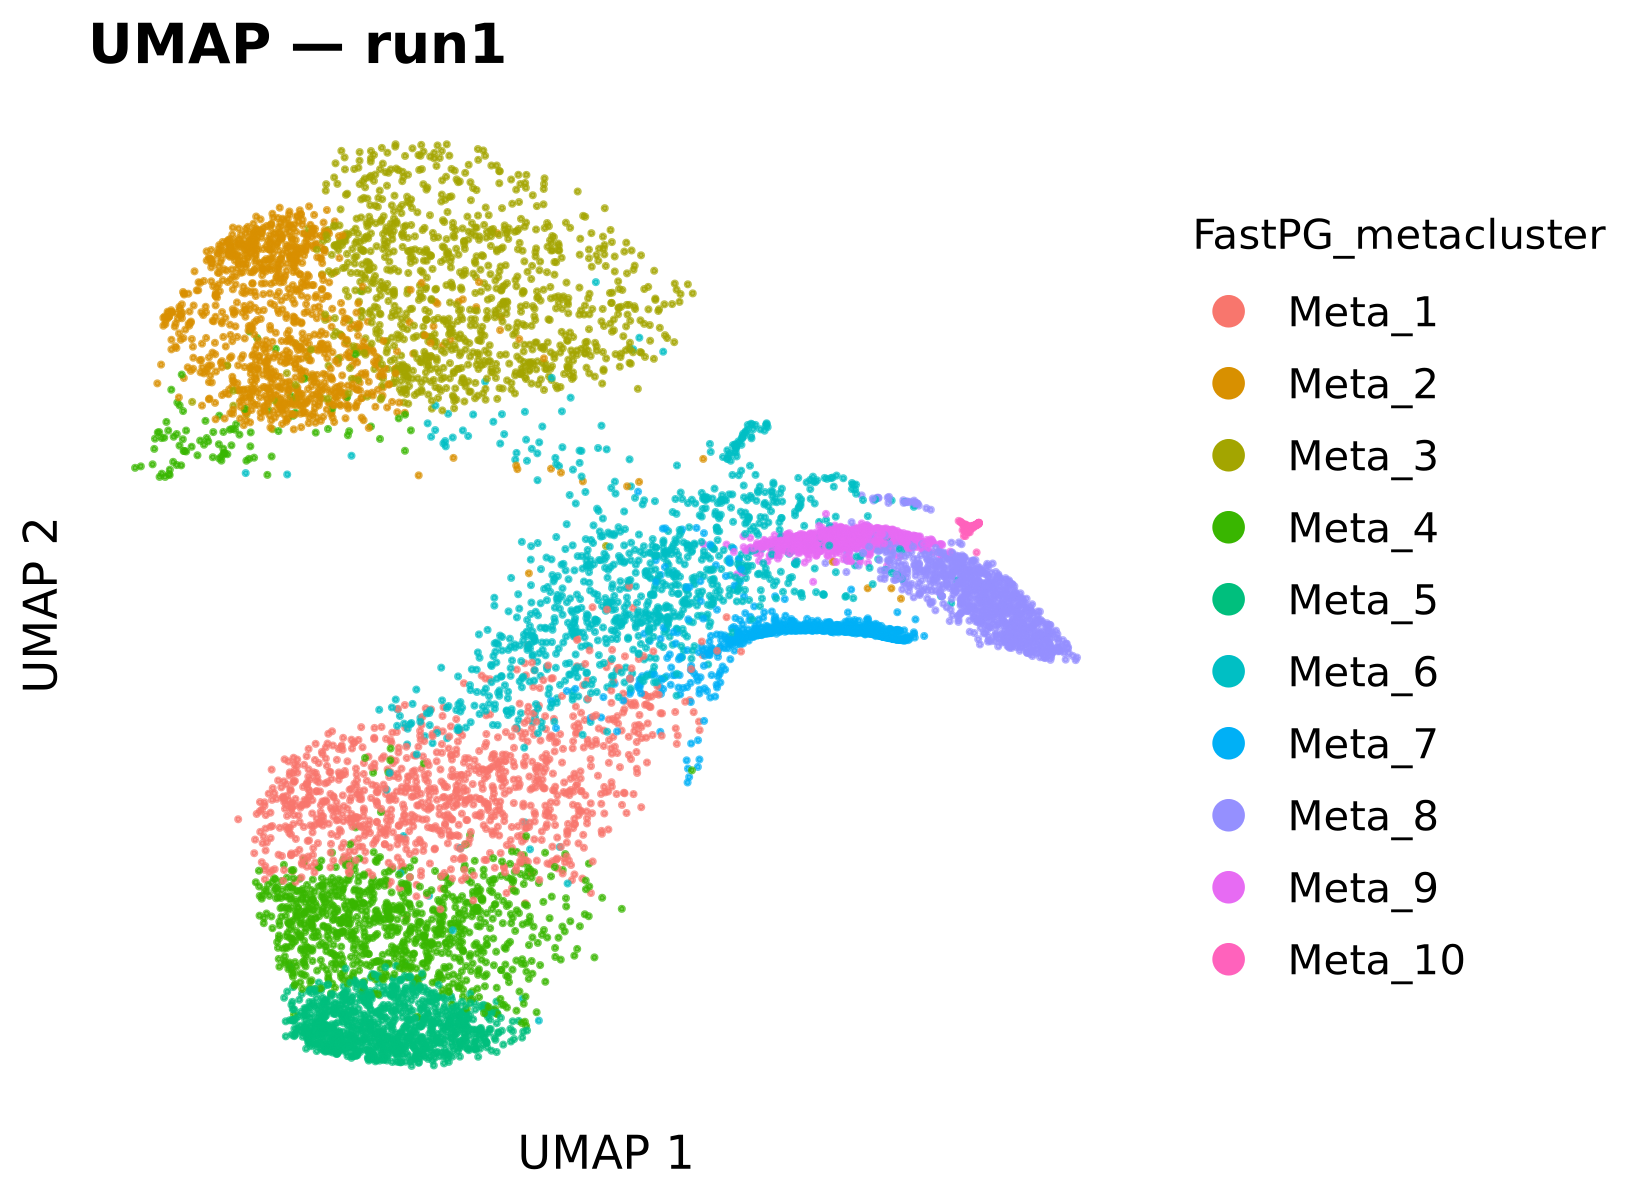

In [14]:
options(repr.plot.width=5.5, repr.plot.height=4, repr.plot.res=300)
gg = project$plot_umap(max_cells_per_cluster=1000)
gg 


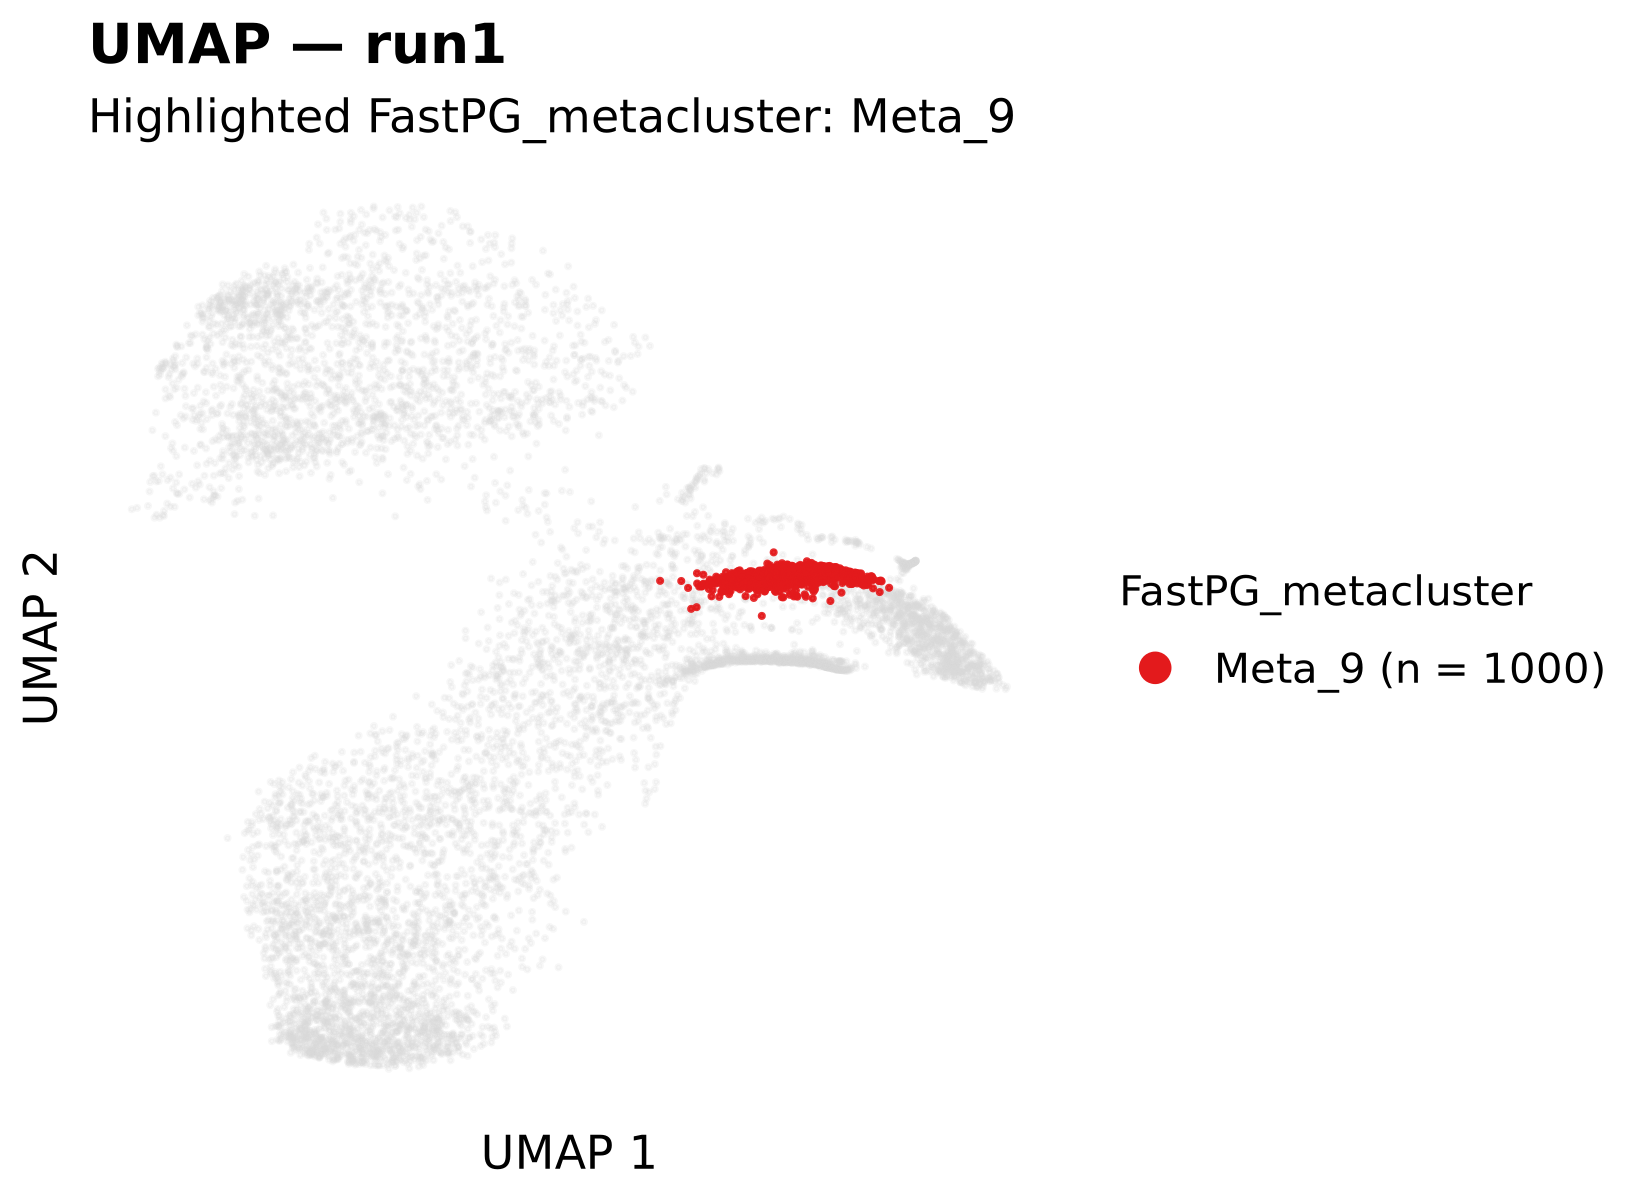

In [15]:
options(repr.plot.width=5.5, repr.plot.height=4, repr.plot.res=300)
gg = project$plot_umap(max_cells_per_cluster=1000, highlight_cluster = "Meta_9", highlight_color = "#E31A1C")
gg 



### Feature plot

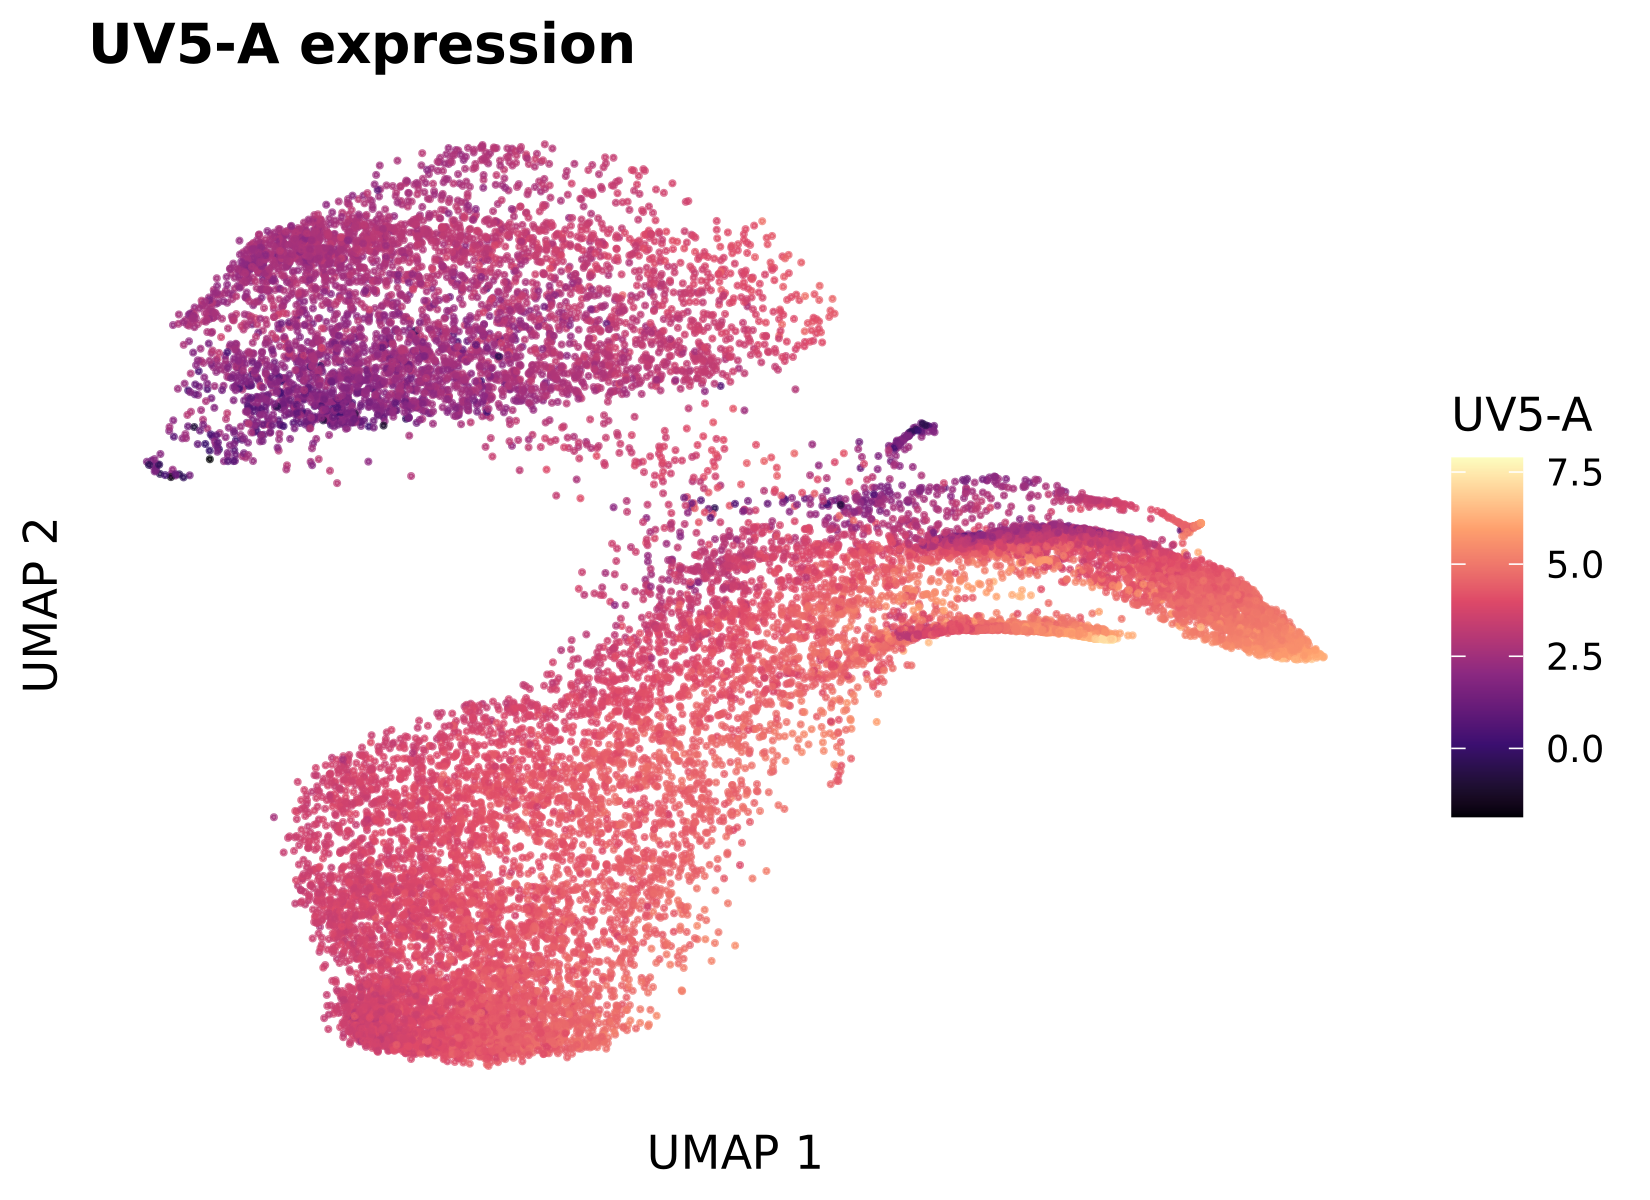

In [17]:
options(repr.plot.width=5.5, repr.plot.height=4, repr.plot.res=300)
project$plot_feature_expression("UV5-A")


### Dotplot

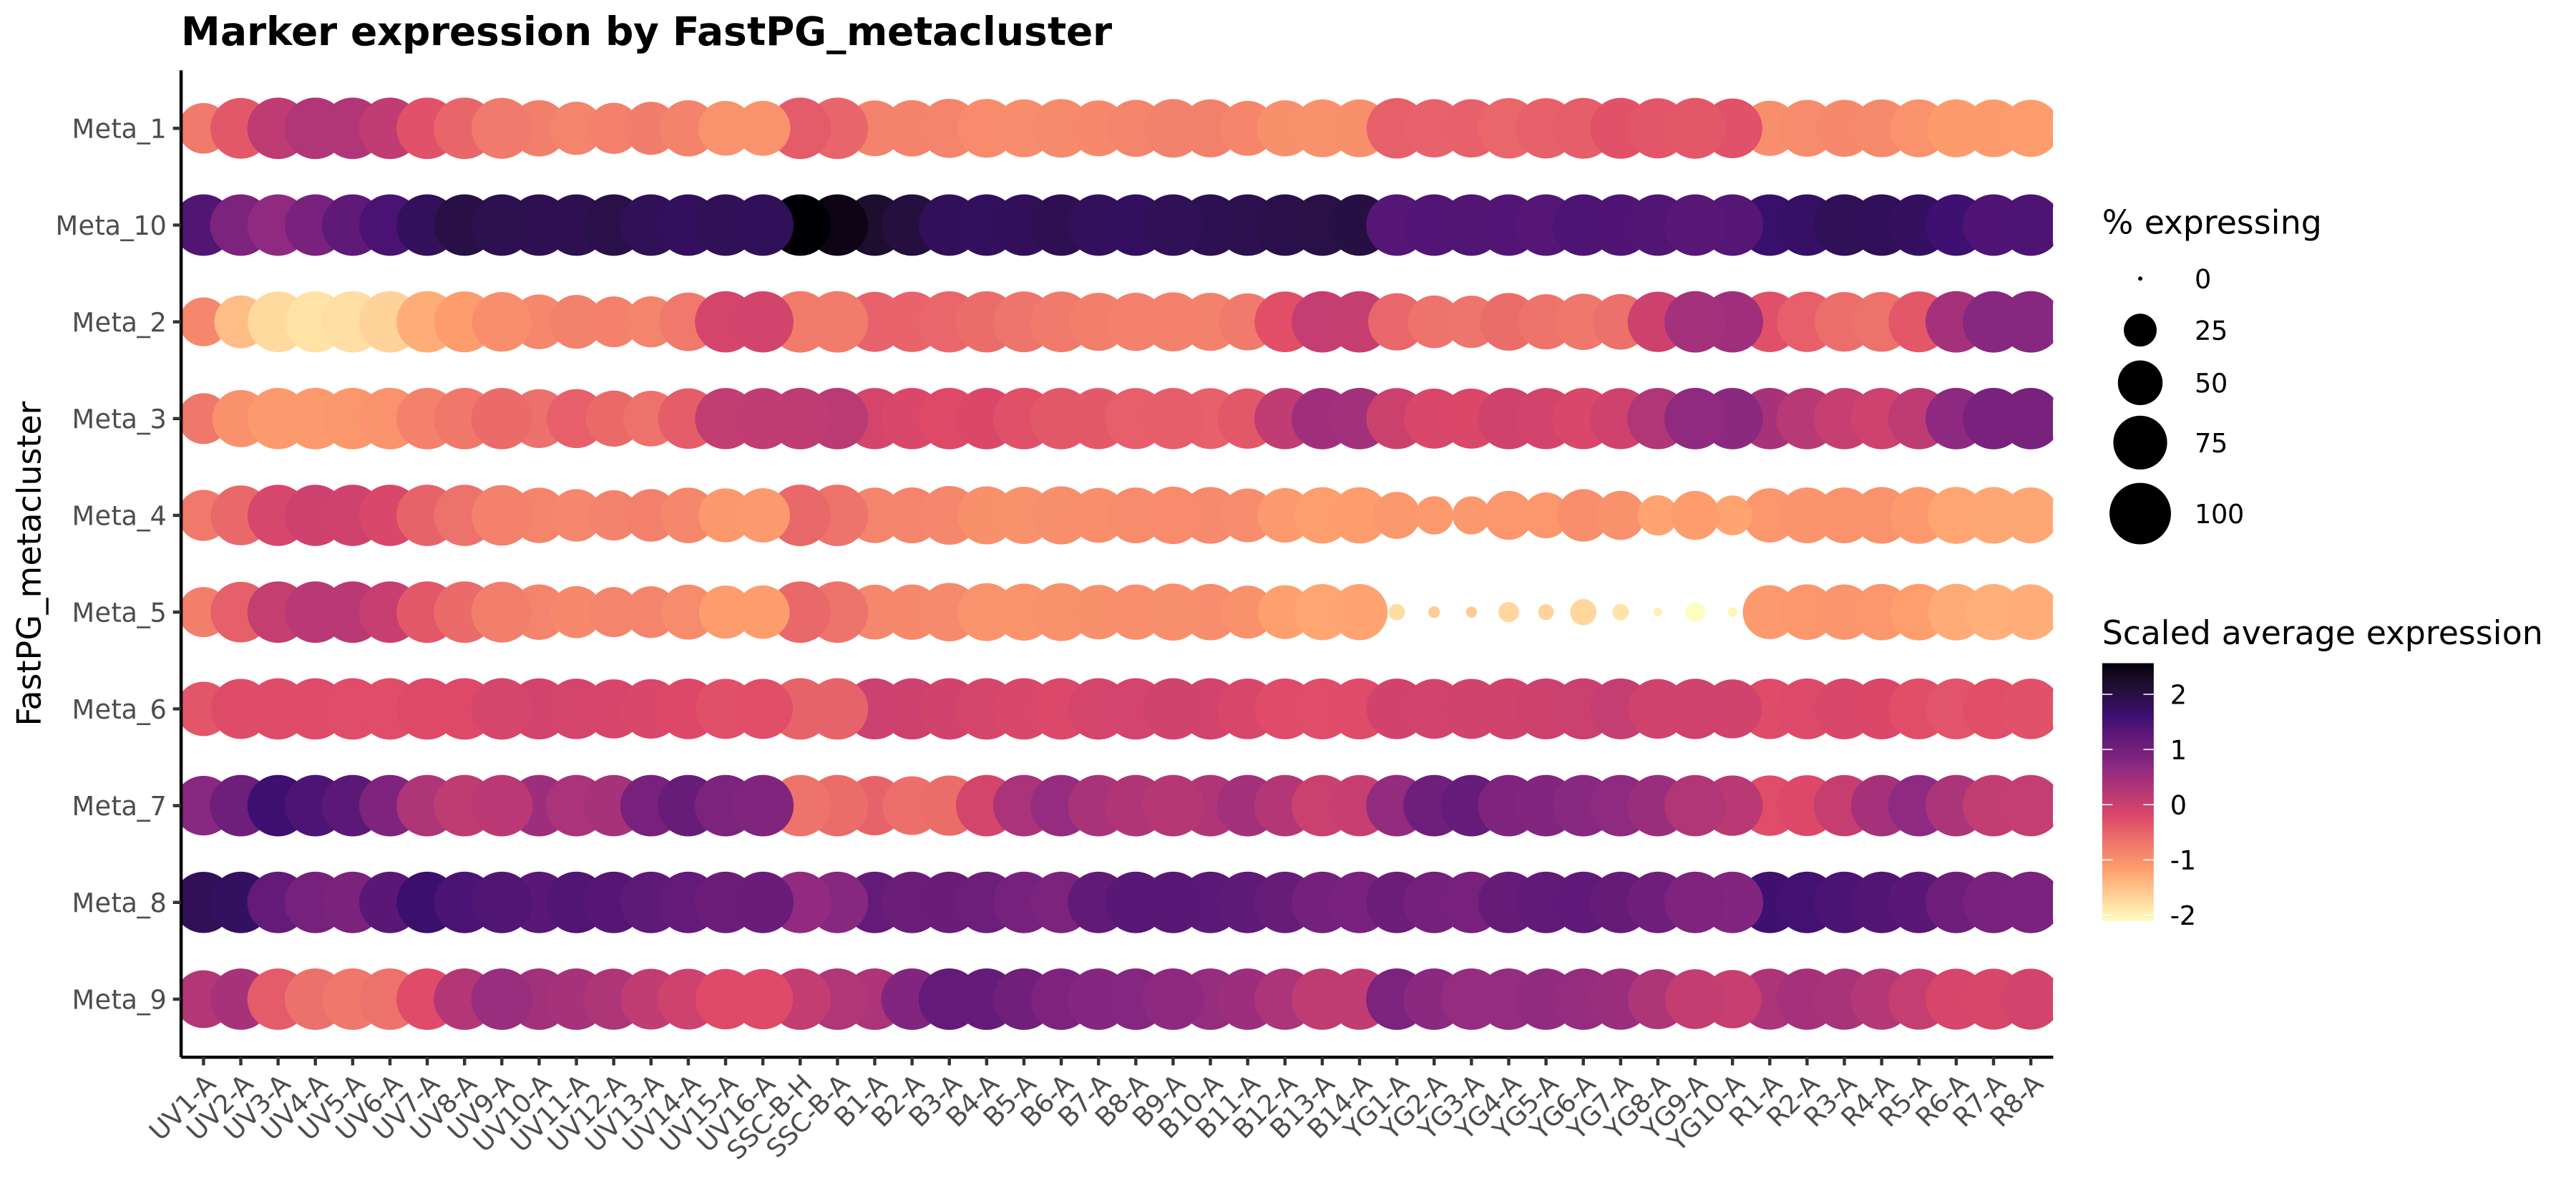

In [18]:
options(repr.plot.width=12, repr.plot.height=5.5, repr.plot.res=300)
project$plot_dotplot(cluster_markers)


### heatmap plot

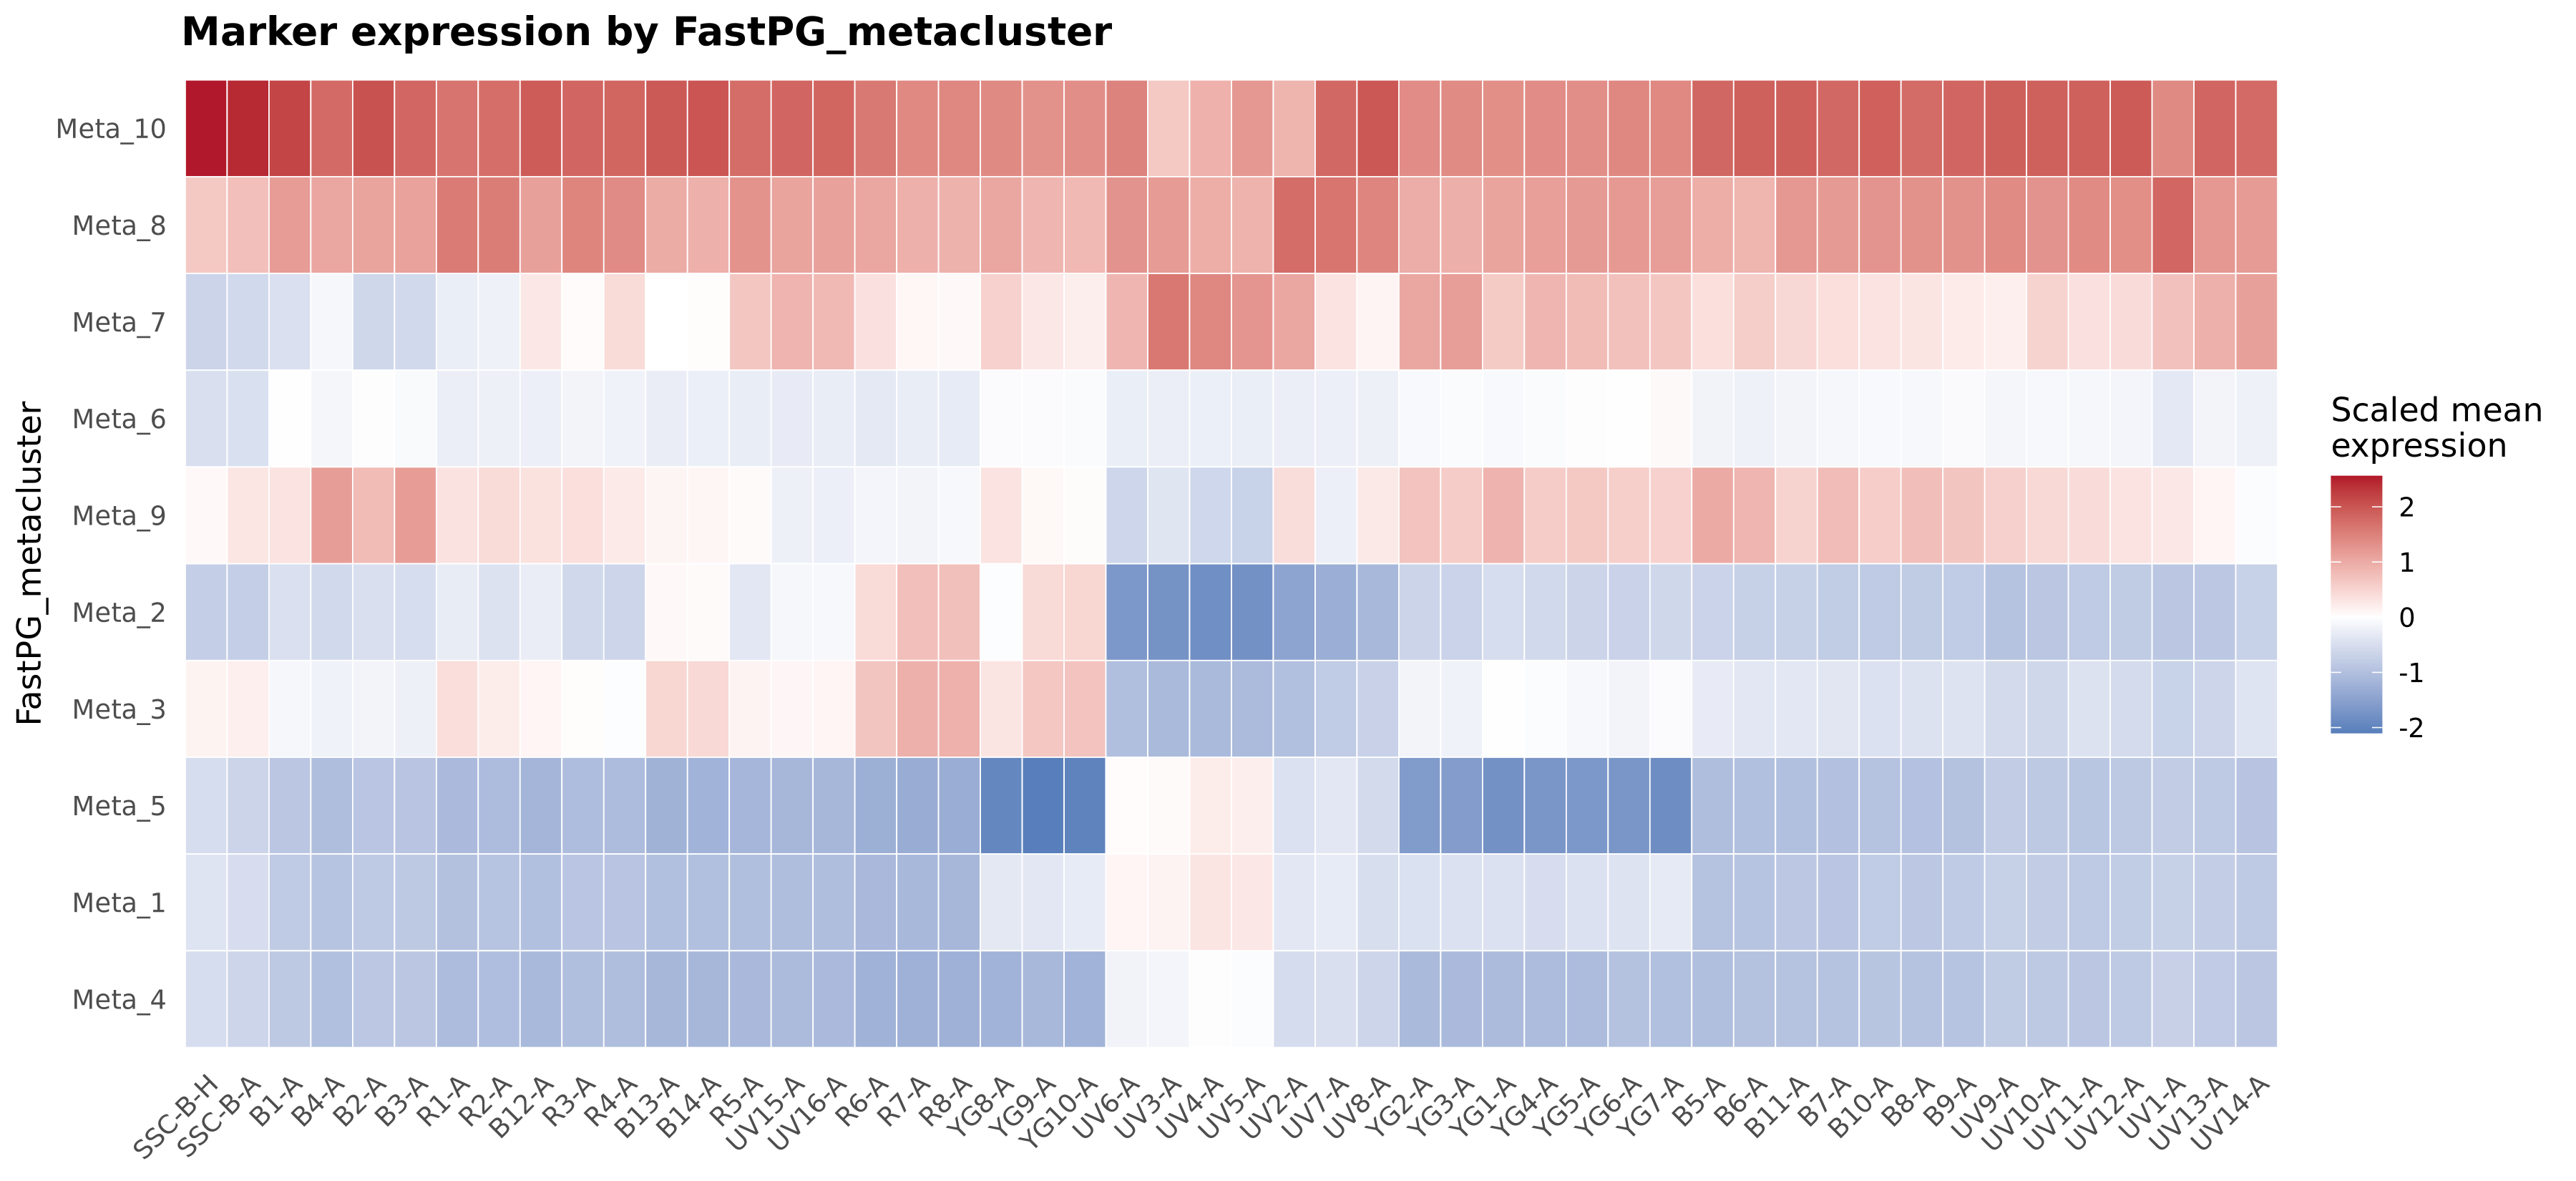

In [19]:
options(repr.plot.width=12, repr.plot.height=5.5, repr.plot.res=300)
project$plot_expression_heatmap(markers = cluster_markers)


In [21]:
project$get_metacluster_counts()

FastPG_metacluster,n_cells
<chr>,<int>
Meta_1,826412
Meta_10,91
Meta_2,239575
Meta_3,337023
Meta_4,327442
Meta_5,148476
Meta_6,89637
Meta_7,2601
Meta_8,15529


# 2nd clustering run

## re-run clustering 

In [ ]:
# It is possible to run the clustering a second time
project$run_harmony_umap_flowsom_fastpg(result_name = 'run2', 
                                        data = project$clustering_results[['run1']]$data, 
                                        metacluster_col = 'FastPG_metacluster',
                                        markers = cluster_markers, 
                                        exclude_metaclusters = c(1,9))

# export data and project status separately and import

## export data and project status

In [42]:
# Large, relatively stable event/sample data
saveRDS(
  project$samples,
  file = "~/workspace/flow/lymphoid_samples.rds",
  compress = FALSE
)


In [95]:
# Smaller, frequently updated analysis state
project_status <- list(
  format = "cytoTerra_project_status",
  version = 1L,

  sample_ids = project$sample_ids,
  sample_names = project$sample_names,
  sample_meta = project$sample_meta,

  metadata = project$metadata,
  channel_labels = project$channel_labels,

  gating_trees = project$gating_trees,
  clustering_results = project$clustering_results,
  active = project$active
)

saveRDS(
  project_status,
  file = "~/workspace/flow/lymphoid_status.rds"
)


## import data and create the new project

In [7]:
samples_dat <- readRDS("~/workspace/flow/lymphoid_samples.rds")
project_status <- readRDS("~/workspace/flow/lymphoid_status.rds") 


In [8]:
project <- CytoTerraProject$new()

project$samples <- samples_dat
project$sample_ids <- project_status$sample_ids
project$sample_names <- project_status$sample_names
project$sample_meta <- project_status$sample_meta

project$metadata <- project_status$metadata
project$channel_labels <- project_status$channel_labels
project$gating_trees <- project_status$gating_trees
project$clustering_results <- project_status$clustering_results
project$active <- project_status$active

# export as a big file

In [ ]:
# also can export as one project file
saveRDS(project, file = file_name)

In [ ]:
# load back 
project = readRDS(file = file_name)